# Summary Plot

Load precomputed layerwise summaries and plot the main regression/RSA/RDM figures without recomputing analyses.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / 'ismir2026' / 'natural_sound_align').exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from ismir2026.natural_sound_align.cache_summary import COMPILED_ROOT, load_compiled_summaries, load_cached_rsa_payload, select_plot_summary
from ismir2026.natural_sound_align.rsa import plot_model_vs_human_rdm

dataset = 'NH2015'  # 'NH2015', 'N2015', or 'B2021'
layer_mode = 'best'  # 'final' or 'best'

regression_all, rsa_all = load_compiled_summaries(compiled_root=COMPILED_ROOT)

def resolve_dataset(requested, regression_table, rsa_table):
    reg_sets = set(regression_table['dataset_name'].unique())
    rsa_sets = set(rsa_table['dataset_name'].unique())
    available = sorted(reg_sets & rsa_sets)
    if not available:
        raise ValueError('No overlapping datasets between regression and RSA tables.')
    if requested not in available:
        print(f"Requested dataset '{requested}' not found. Using '{available[0]}' instead.")
        return available[0]
    return requested

dataset = resolve_dataset(dataset, regression_all, rsa_all)

regression_summary = select_plot_summary(
    regression_all,
    dataset_name=dataset,
    layer_mode=layer_mode,
    metric_column='cv_subject_mean',
)
rsa_summary = select_plot_summary(
    rsa_all,
    dataset_name=dataset,
    layer_mode=layer_mode,
    metric_column='median_spearman',
)

foundation_regression = regression_summary.query("model_name != 'SPECTEMP'").reset_index(drop=True)
spectemp_regression = regression_summary.query("model_name == 'SPECTEMP'").reset_index(drop=True)
foundation_rsa = rsa_summary.query("model_name != 'SPECTEMP'").reset_index(drop=True)
spectemp_rsa = rsa_summary.query("model_name == 'SPECTEMP'").reset_index(drop=True)

layer_mode_label = 'Best layer' if layer_mode == 'best' else 'Final layer'

display(regression_summary)
display(rsa_summary)


,model_name,representation_name,n_voxels,n_splits,source_dim,median_noise_corrected_r2,mean_noise_corrected_r2,median_noise_corrected_r2_raw,mean_noise_corrected_r2_raw,median_r2,...,cv_subject_mean,cv_subject_median,cv_subject_sem,cv_subject_std,value_column,dataset_name,layer_index,layer_depth,is_final,result_dir
0,MULAN,layer_09,7694,10,1024,0.765762,0.721824,0.765762,0.770365,0.346425,...,0.761989,0.758771,0.014229,0.040247,median_r2_test_c,NH2015,9.0,9,False,/home/hjkim/selective_auditory/ismir2026/natur...
1,MERT,layer_05,7694,10,1024,0.749149,0.718122,0.749149,0.794878,0.343446,...,0.753849,0.747028,0.022300,0.063074,median_r2_test_c,NH2015,5.0,5,False,/home/hjkim/selective_auditory/ismir2026/natur...
2,CLAP,layer_03,7694,10,768,0.751750,0.721248,0.751750,0.776488,0.341161,...,0.750429,0.745370,0.016307,0.046123,median_r2_test_c,NH2015,3.0,3,False,/home/hjkim/selective_auditory/ismir2026/natur...
3,MERT95,layer_05,7694,10,768,0.735700,0.710898,0.735700,0.764776,0.346186,...,0.740025,0.731421,0.021279,0.060186,median_r2_test_c,NH2015,5.0,5,False,/home/hjkim/selective_auditory/ismir2026/natur...
4,CLAP_MUSIC_SPEECH,layer_03,7694,10,1024,0.732772,0.699986,0.732772,0.748630,0.318240,...,0.728712,0.729563,0.023148,0.065474,median_r2_test_c,NH2015,3.0,3,False,/home/hjkim/selective_auditory/ismir2026/natur...
5,MUSICGEN_SMALL,layer_10,7694,10,1024,0.658713,0.658327,0.658713,0.734803,0.303598,...,0.661185,0.662964,0.016581,0.046899,median_r2_test_c,NH2015,10.0,10,False,/home/hjkim/selective_auditory/ismir2026/natur...
6,WAV2VEC2,layer_03,7694,10,768,0.656898,0.650834,0.656898,0.707796,0.300646,...,0.660553,0.652561,0.021654,0.061246,median_r2_test_c,NH2015,3.0,3,False,/home/hjkim/selective_auditory/ismir2026/natur...
7,MUSICGEN_LARGE,layer_34,7694,10,2048,0.609617,0.606027,0.609617,0.662714,0.270298,...,0.610923,0.616054,0.020342,0.057535,median_r2_test_c,NH2015,34.0,34,False,/home/hjkim/selective_auditory/ismir2026/natur...
8,MUSICGEN_MELODY_LARGE,layer_46,7694,10,2048,0.602491,0.598647,0.602491,0.658540,0.240379,...,0.604326,0.598324,0.023068,0.065246,median_r2_test_c,NH2015,46.0,46,False,/home/hjkim/selective_auditory/ismir2026/natur...
9,MUSICGEN_MEDIUM,layer_30,7694,10,1536,0.577550,0.577631,0.577550,0.628734,0.249882,...,0.579778,0.593415,0.025802,0.072979,median_r2_test_c,NH2015,30.0,30,False,/home/hjkim/selective_auditory/ismir2026/natur...


,model_name,representation_name,n_repetitions,n_participants,n_splits,mean_spearman,median_spearman,participant_sem,mean_leave_one_out_neural_spearman,dataset_name,layer_index,layer_depth,is_final,result_dir
0,MERT,layer_04,8,8,10,0.504783,0.510128,0.009904,0.754764,NH2015,4.0,4,False,/home/hjkim/selective_auditory/ismir2026/natur...
1,MERT95,layer_05,8,8,10,0.497703,0.497986,0.006947,0.754764,NH2015,5.0,5,False,/home/hjkim/selective_auditory/ismir2026/natur...
2,MULAN,layer_06,8,8,10,0.476230,0.480516,0.007083,0.754764,NH2015,6.0,6,False,/home/hjkim/selective_auditory/ismir2026/natur...
3,CLAP_MUSIC_SPEECH,layer_03,8,8,10,0.425292,0.431201,0.006857,0.754764,NH2015,3.0,3,False,/home/hjkim/selective_auditory/ismir2026/natur...
4,CLAP,layer_02,8,8,10,0.421643,0.420338,0.005212,0.754764,NH2015,2.0,2,False,/home/hjkim/selective_auditory/ismir2026/natur...
5,SPECTEMP,avgpool,8,8,10,0.412462,0.410600,0.011872,0.754764,NH2015,NaN,0,False,/home/hjkim/selective_auditory/ismir2026/natur...
6,WAV2VEC2,layer_02,8,8,10,0.378551,0.383810,0.009462,0.754764,NH2015,2.0,2,False,/home/hjkim/selective_auditory/ismir2026/natur...
7,MUSICGEN_SMALL,layer_14,8,8,10,0.370816,0.363087,0.014120,0.754764,NH2015,14.0,14,False,/home/hjkim/selective_auditory/ismir2026/natur...
8,MUSICGEN_LARGE,layer_34,8,8,10,0.350769,0.342905,0.008705,0.754764,NH2015,34.0,34,False,/home/hjkim/selective_auditory/ismir2026/natur...
9,MUSICGEN_MELODY_LARGE,layer_47,8,8,10,0.331592,0.326455,0.012353,0.754764,NH2015,47.0,47,False,/home/hjkim/selective_auditory/ismir2026/natur...


## Regression & RSA Summary

,dataset_name,model_name,representation_name,cv_subject_mean,cv_subject_median,median_noise_corrected_r2
0,NH2015,MULAN,layer_09,0.761989,0.758771,0.765762
1,NH2015,MERT,layer_05,0.753849,0.747028,0.749149
2,NH2015,CLAP,layer_03,0.750429,0.745370,0.751750
3,NH2015,MERT95,layer_05,0.740025,0.731421,0.735700
4,NH2015,CLAP_MUSIC_SPEECH,layer_03,0.728712,0.729563,0.732772
5,NH2015,MUSICGEN_SMALL,layer_10,0.661185,0.662964,0.658713
6,NH2015,WAV2VEC2,layer_03,0.660553,0.652561,0.656898
7,NH2015,MUSICGEN_LARGE,layer_34,0.610923,0.616054,0.609617
8,NH2015,MUSICGEN_MELODY_LARGE,layer_46,0.604326,0.598324,0.602491
9,NH2015,MUSICGEN_MEDIUM,layer_30,0.579778,0.593415,0.577550


,dataset_name,model_name,representation_name,mean_spearman,median_spearman,n_participants
0,NH2015,MERT,layer_04,0.504783,0.510128,8
1,NH2015,MERT95,layer_05,0.497703,0.497986,8
2,NH2015,MULAN,layer_06,0.476230,0.480516,8
3,NH2015,CLAP_MUSIC_SPEECH,layer_03,0.425292,0.431201,8
4,NH2015,CLAP,layer_02,0.421643,0.420338,8
5,NH2015,SPECTEMP,avgpool,0.412462,0.410600,8
6,NH2015,WAV2VEC2,layer_02,0.378551,0.383810,8
7,NH2015,MUSICGEN_SMALL,layer_14,0.370816,0.363087,8
8,NH2015,MUSICGEN_LARGE,layer_34,0.350769,0.342905,8
9,NH2015,MUSICGEN_MELODY_LARGE,layer_47,0.331592,0.326455,8


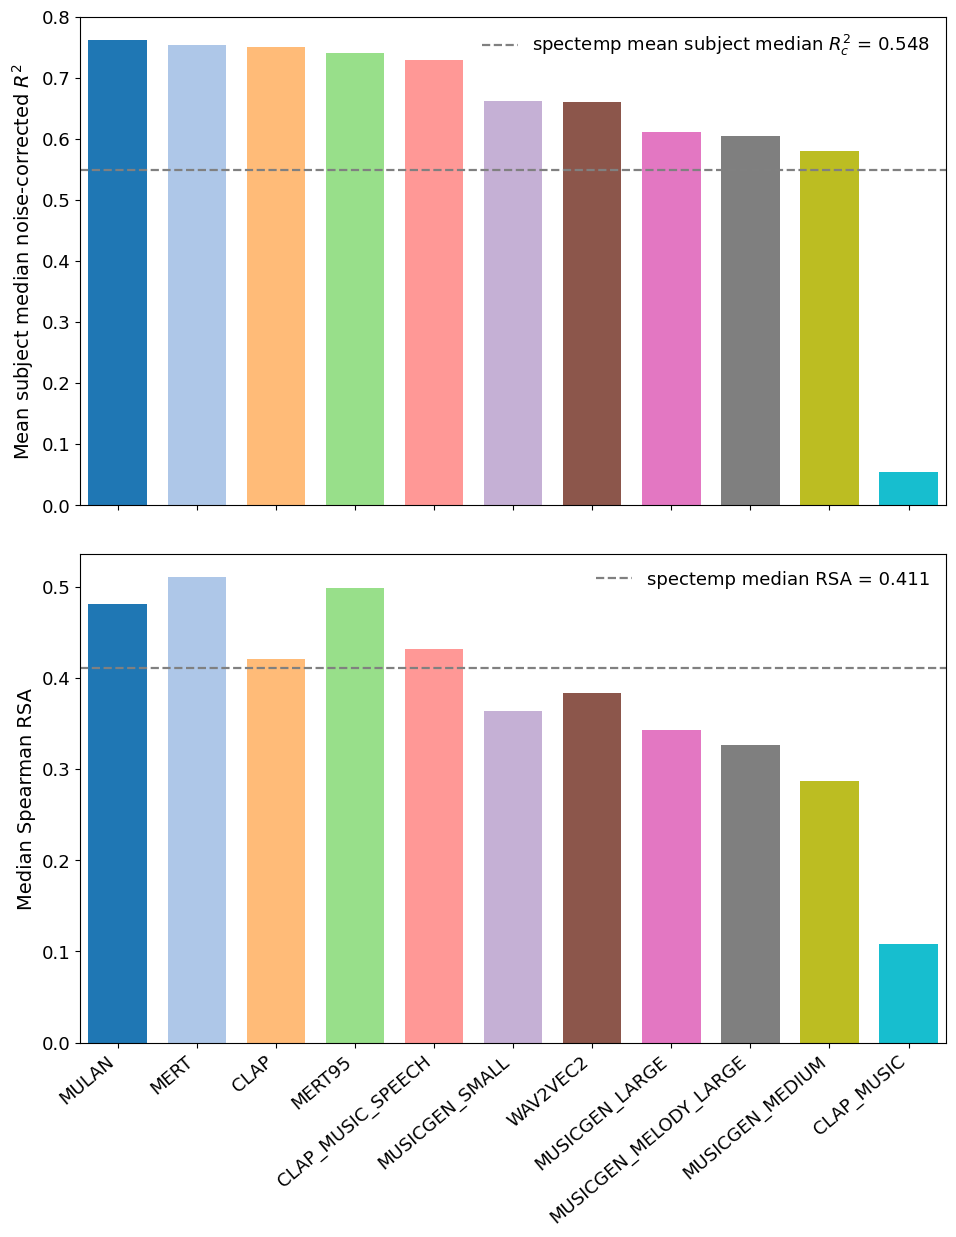

In [14]:
display(regression_summary[['dataset_name', 'model_name', 'representation_name', 'cv_subject_mean', 'cv_subject_median', 'median_noise_corrected_r2']])
display(rsa_summary[['dataset_name', 'model_name', 'representation_name', 'mean_spearman', 'median_spearman', 'n_participants']])

default_model_order = [
    'CLAP',
    'CLAP_MUSIC',
    'CLAP_MUSIC_SPEECH',
    'MULAN',
    'MERT',
    'MERT95',
    'WAV2VEC2',
    'MUSICGEN_SMALL',
    'MUSICGEN_MEDIUM',
    'MUSICGEN_LARGE',
    'MUSICGEN_MELODY_LARGE',
]

available_models = sorted(
    set(foundation_regression['model_name'].unique()) | set(foundation_rsa['model_name'].unique()),
    key=lambda name: (default_model_order.index(name) if name in default_model_order else len(default_model_order), name),
)

reg_plot = (
    foundation_regression.set_index('model_name')
    .reindex(available_models)
    .reset_index()
    .rename(columns={'index': 'model_name'})
)
rsa_plot = (
    foundation_rsa.set_index('model_name')
    .reindex(available_models)
    .reset_index()
    .rename(columns={'index': 'model_name'})
)

# Shared-x requires one common order; sort by regression score descending.
order_df = reg_plot[['model_name', 'cv_subject_mean']].copy()
order_df['cv_subject_mean'] = order_df['cv_subject_mean'].fillna(float('-inf'))
ordered_models = order_df.sort_values('cv_subject_mean', ascending=False)['model_name'].tolist()

reg_plot = reg_plot.set_index('model_name').reindex(ordered_models).reset_index()
rsa_plot = rsa_plot.set_index('model_name').reindex(ordered_models).reset_index()

x = list(range(len(ordered_models)))
bar_colors = plt.get_cmap('tab20')(pd.Series(range(len(ordered_models))) / max(len(ordered_models), 1))

fig_width = max(8.2, 0.68 * len(ordered_models) + 2.2)
fig_height = fig_width * (4.0 / 3.0)
fig, axes = plt.subplots(2, 1, figsize=(fig_width, fig_height), sharex=True)

baseline_subject_mean = float(spectemp_regression['cv_subject_mean'].iloc[0]) if len(spectemp_regression) else None
axes[0].bar(x, reg_plot['cv_subject_mean'], color=bar_colors, width=0.74)
if baseline_subject_mean is not None:
    axes[0].axhline(
        baseline_subject_mean,
        linestyle='--',
        color='gray',
        linewidth=1.6,
        label=f"spectemp mean subject median $R^2_c$ = {baseline_subject_mean:.3f}",
    )
    axes[0].legend(frameon=False, fontsize=13, loc='upper right')
axes[0].set_ylabel('Mean subject median noise-corrected $R^2$', fontsize=14)
axes[0].tick_params(axis='y', labelsize=13)
axes[0].margins(x=0.01)

baseline_rsa = float(spectemp_rsa['median_spearman'].iloc[0]) if len(spectemp_rsa) else None
axes[1].bar(x, rsa_plot['median_spearman'], color=bar_colors, width=0.74)
if baseline_rsa is not None:
    axes[1].axhline(
        baseline_rsa,
        linestyle='--',
        color='gray',
        linewidth=1.6,
        label=f"spectemp median RSA = {baseline_rsa:.3f}",
    )
    axes[1].legend(frameon=False, fontsize=13, loc='upper right')
axes[1].set_ylabel('Median Spearman RSA', fontsize=14)
axes[1].tick_params(axis='y', labelsize=13)
axes[1].margins(x=0.01)

axes[1].set_xticks(x)
axes[1].set_xticklabels(ordered_models, rotation=40, ha='right', fontsize=13)

fig.subplots_adjust(left=0.10, right=0.995, bottom=0.20, top=0.995, hspace=0.10)
plt.show()


## Human vs Model RDM

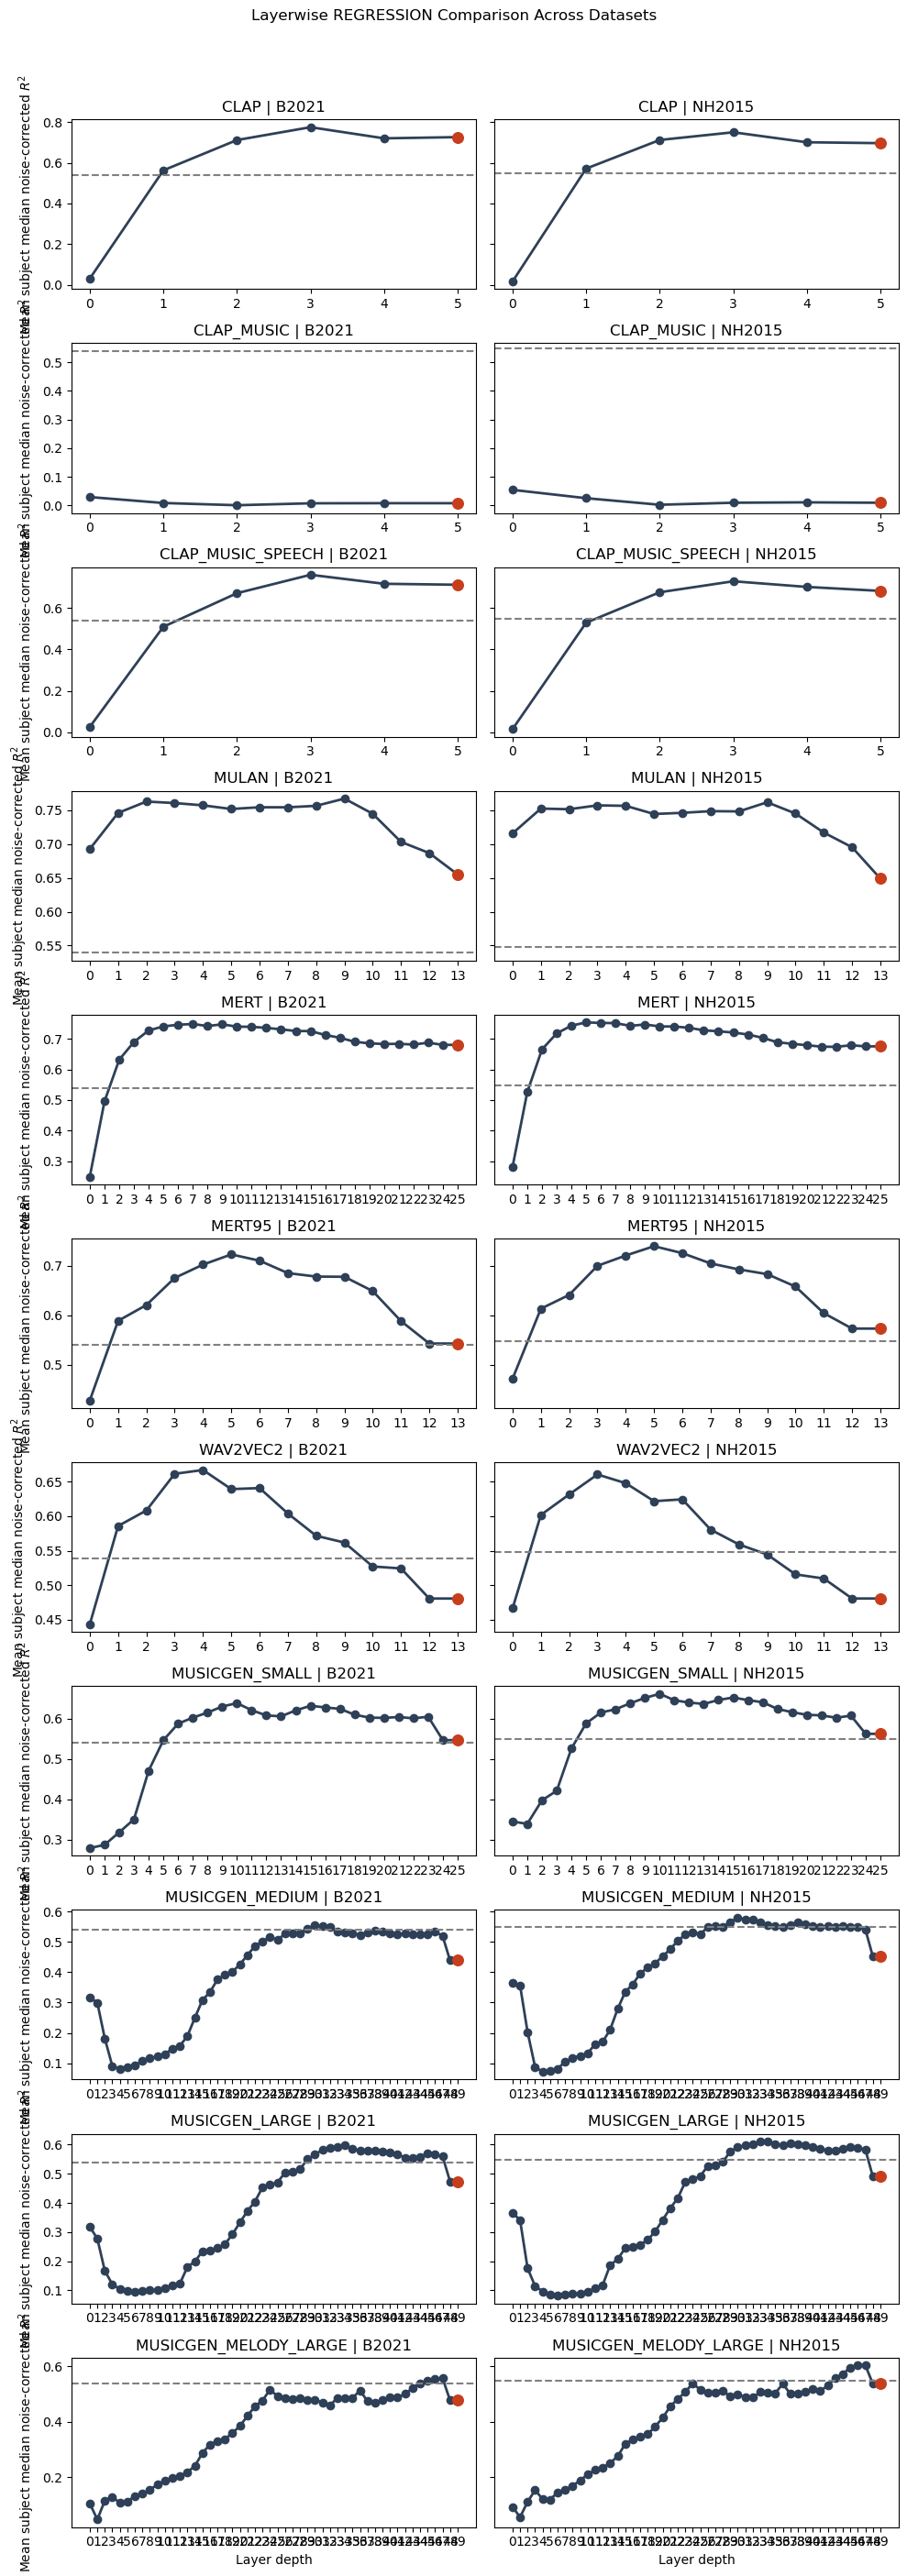

In [4]:
comparison_mode = 'regression'  # 'regression' or 'RSA'

mode_key = comparison_mode.strip().lower()
if mode_key == 'regression':
    layerwise_table = regression_all
    metric_column = 'cv_subject_mean'
    y_label = 'Mean subject median noise-corrected $R^2$'
    line_color = '#2E4057'
elif mode_key == 'rsa':
    layerwise_table = rsa_all
    metric_column = 'median_spearman'
    y_label = 'Median Spearman RSA'
    line_color = '#048A81'
else:
    raise ValueError("comparison_mode must be either 'regression' or 'RSA'.")

default_model_order = ['CLAP', 'CLAP_MUSIC', 'CLAP_MUSIC_SPEECH', 'MULAN', 'MERT', 'MERT95', 'WAV2VEC2', 'MUSICGEN_SMALL', 'MUSICGEN_MEDIUM', 'MUSICGEN_LARGE', 'MUSICGEN_MELODY_LARGE']
available_models = [model for model in default_model_order if model in layerwise_table['model_name'].unique()]
comparison_models = available_models  # replace with a custom list if you want a subset

if not comparison_models:
    raise ValueError('No models available for comparison in the compiled summaries.')

model_dataset_sets = []
for model_name in comparison_models:
    datasets_for_model = set(layerwise_table.query("model_name == @model_name")['dataset_name'].unique())
    if datasets_for_model:
        model_dataset_sets.append(datasets_for_model)

if model_dataset_sets:
    datasets = sorted(set.intersection(*model_dataset_sets))
else:
    datasets = []

if not datasets:
    datasets = sorted(layerwise_table['dataset_name'].unique())
    print("No common datasets across selected models. Plotting all available datasets instead:", datasets)

fig_height = max(10, 2.5 * len(comparison_models))
fig_width = max(10, 4 * len(datasets))
fig, axes = plt.subplots(nrows=len(comparison_models), ncols=len(datasets), figsize=(fig_width, fig_height), sharex=False, sharey='row', squeeze=False)

for row_index, model_name in enumerate(comparison_models):
    for col_index, dataset_name in enumerate(datasets):
        ax = axes[row_index, col_index]
        layerwise = layerwise_table.query("dataset_name == @dataset_name and model_name == @model_name").sort_values('layer_depth').reset_index(drop=True).copy()
        if layerwise.empty:
            ax.set_axis_off()
            continue
        if (layerwise['layer_depth'] < 0).any():
            nonfinal_depths = layerwise.loc[~layerwise['is_final'], 'layer_depth']
            fallback_depth = int(nonfinal_depths.max()) + 1 if len(nonfinal_depths) else 0
            layerwise.loc[layerwise['is_final'], 'layer_depth'] = fallback_depth

        ax.plot(layerwise['layer_depth'], layerwise[metric_column], marker='o', color=line_color, linewidth=2)
        final_row = layerwise.query('is_final').iloc[0]
        ax.scatter([final_row['layer_depth']], [final_row[metric_column]], color='#C73E1D', s=70, zorder=3)

        baseline_row = layerwise_table.query("dataset_name == @dataset_name and model_name == 'SPECTEMP'")
        if len(baseline_row):
            ax.axhline(float(baseline_row.iloc[0][metric_column]), linestyle='--', color='gray', linewidth=1.5)

        ax.set_title(f'{model_name} | {dataset_name}')
        ax.set_xticks(layerwise['layer_depth'])
        if row_index == len(comparison_models) - 1:
            ax.set_xlabel('Layer depth')
        if col_index == 0:
            ax.set_ylabel(y_label)

fig.suptitle(f'Layerwise {comparison_mode.upper()} Comparison Across Datasets', y=1.02)
fig.tight_layout()
plt.show()
